In [26]:
!pip install -q pandas matplotlib scipy requests

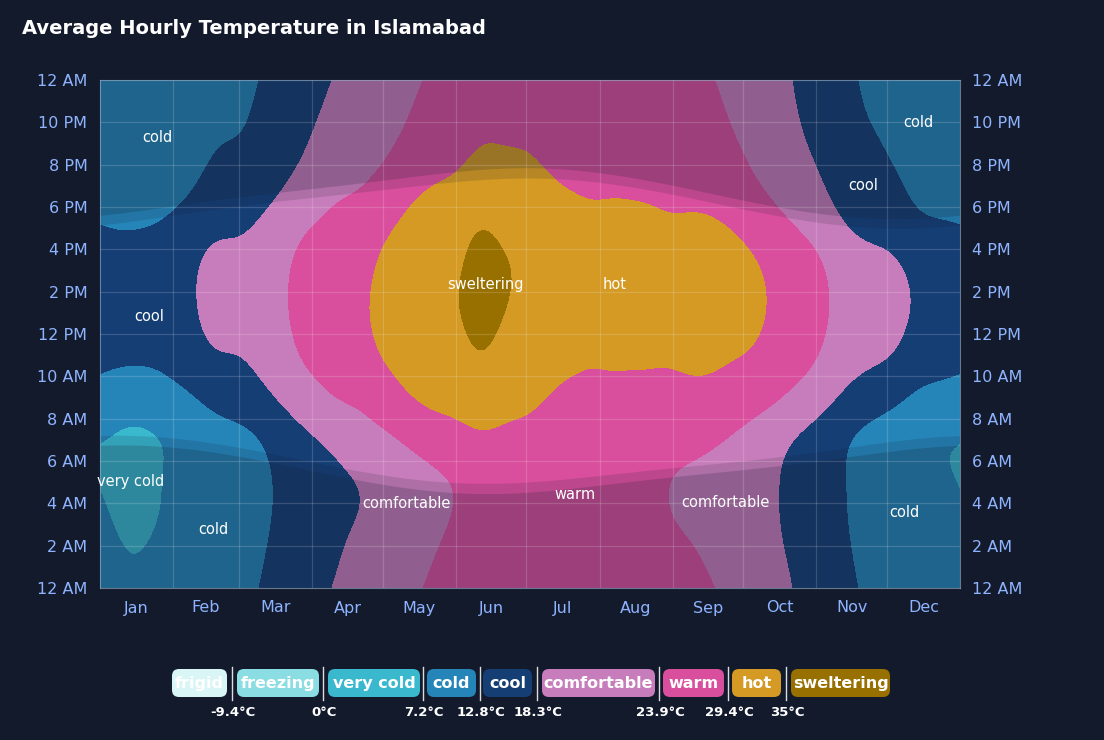

In [2]:
"""
WeatherSpark-style "Average Hourly Temperature" chart (Islamabad, Celsius).
"""
import datetime as dt
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy.ndimage import gaussian_filter, distance_transform_edt, label
from scipy.interpolate import RectBivariateSpline

# ───────────────────────── CONFIG ─────────────────────────
CITY = "Islamabad"
LAT, LON = 33.68, 73.04
TZ_NAME, TZ_OFFSET = "Asia/Karachi", 5.0
YEAR_FROM, YEAR_TO = 2015, 2025

W, H = 1084, 720
AX_L, AX_R, AX_T, AX_B = 90, 950, 70, 578

BG = "#131a2c"
TICK = "#8fb4ff"
NIGHT_ALPHA, TWILIGHT_ALPHA = 0.30, 0.14
LABEL_MIN_RADIUS = 9

C_THRESH = [-9.4, 0, 7.2, 12.8, 18.3, 23.9, 29.4, 35]
LEVELS = [-100] + C_THRESH + [100]
NAMES = ["frigid", "freezing", "very cold", "cold", "cool",
         "comfortable", "warm", "hot", "sweltering"]
PLOT_COLORS = ["#D9F5F5", "#8ADDE2", "#39B8CE",
  "#2585B8", "#153E75", "#C77DBB",
  "#D94F9D", "#D49A24", "#987000"]
LEGEND_COLORS = ["#D9F5F5", "#8ADDE2", "#39B8CE",
  "#2585B8", "#153E75", "#C77DBB",
  "#D94F9D", "#D49A24", "#987000"]
LEGEND_PILLS = [(162, 55), (227, 82), (318, 92), (417, 49), (473, 49),
                (532, 113), (653, 61), (722, 49), (781, 99)]
LEGEND_SEPS = [222, 313, 413, 470, 527, 649, 718, 776]

MONTH_DAYS = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
MONTH_START = np.concatenate([[0], np.cumsum(MONTH_DAYS)])
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# ───────────────────────── DATA ─────────────────────────
def fetch_hourly():
    params = dict(latitude=LAT, longitude=LON,
                  start_date=f"{YEAR_FROM}-01-01", end_date=f"{YEAR_TO}-12-31",
                  hourly="temperature_2m", timezone=TZ_NAME)
    r = requests.get("https://archive-api.open-meteo.com/v1/archive",
                     params=params, timeout=180)
    r.raise_for_status()
    h = r.json()["hourly"]
    return pd.DataFrame({"time": pd.to_datetime(h["time"]),
                         "temp": h["temperature_2m"]}).dropna()

def hour_by_day_grid(df):
    md = df["time"].dt.strftime("%m-%d")
    df = df[md != "02-29"].copy()
    df["doy"] = pd.to_datetime("2001-" + df["time"].dt.strftime("%m-%d")).dt.dayofyear
    return df.groupby([df["time"].dt.hour, "doy"])["temp"].mean().unstack().values

def smooth_field(grid, nx, ny):
    g = gaussian_filter(grid, sigma=(0.9, 6), mode="wrap")
    px, py = 30, 3
    g = np.hstack([g[:, -px:], g, g[:, :px]])
    g = np.vstack([g[-py:], g, g[:py]])
    xs = np.arange(-px, 365 + px) + 0.5
    ys = np.arange(-py, 24 + py)
    spl = RectBivariateSpline(ys, xs, g, kx=3, ky=3)
    x = np.linspace(0, 365, nx)
    y = np.linspace(0, 24, ny)
    return np.meshgrid(x, y)[0], np.meshgrid(x, y)[1], spl(y, x)

# ───────────────────────── SUN ─────────────────────────
def solar_hours(doy, zenith_deg):
    g = 2 * np.pi / 365 * (doy - 1)
    eqt = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                    - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))
    dec = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g)
           - 0.006758 * np.cos(2 * g) + 0.000907 * np.sin(2 * g)
           - 0.002697 * np.cos(3 * g) + 0.00148 * np.sin(3 * g))
    lat = np.radians(LAT)
    cosha = (np.cos(np.radians(zenith_deg)) - np.sin(lat) * np.sin(dec)) / (np.cos(lat) * np.cos(dec))
    ha = np.degrees(np.arccos(np.clip(cosha, -1, 1)))
    rise = (720 - 4 * (LON + ha) - eqt) / 60 + TZ_OFFSET
    sset = (720 - 4 * (LON - ha) - eqt) / 60 + TZ_OFFSET
    return rise, sset

# ───────────────────────── PLOT ─────────────────────────
def hour_label(h):
    return f"{(h % 12) or 12} {'AM' if h % 24 < 12 else 'PM'}"

def pill(ov, x, y, w, h, color, text, text_color="white", fs=11, r=7):
    ov.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0,rounding_size={r}",
                                fc=color, ec="none"))
    ov.text(x + w / 2, y + h / 2 + 0.5, text, color=text_color, ha="center", va="center",
            fontsize=fs, fontweight="bold")

def make_figure(df):
    nx, ny = AX_R - AX_L, AX_B - AX_T
    X, Y, Z = smooth_field(hour_by_day_grid(df), nx, ny)

    fig = plt.figure(figsize=(W / 100, H / 100), dpi=100, facecolor=BG)
    ax = fig.add_axes([AX_L / W, 1 - AX_B / H, (AX_R - AX_L) / W, (AX_B - AX_T) / H])
    ax.set_facecolor(BG)

    ax.contourf(X, Y, Z, levels=LEVELS, colors=PLOT_COLORS, zorder=1)

    xs = np.linspace(0, 365, 731)
    doy = xs + 0.5
    sr, ss = solar_hours(doy, 90.833)
    cr, cs = solar_hours(doy, 96.0)
    for (lo, hi, a) in [(0, cr, NIGHT_ALPHA), (cr, sr, TWILIGHT_ALPHA),
                        (ss, cs, TWILIGHT_ALPHA), (cs, 24, NIGHT_ALPHA)]:
        ax.fill_between(xs, lo, hi, color=BG, alpha=a, lw=0, zorder=2)

    ax.vlines(MONTH_START[1:-1], 0, 24, color="white", alpha=0.16, lw=0.9, zorder=3)
    ax.hlines(range(2, 24, 2), 0, 365, color="white", alpha=0.16, lw=0.9, zorder=3)

    band = np.digitize(Z, LEVELS[1:-1])
    for b, name in enumerate(NAMES):
        mask = band == b
        if not mask.any(): continue
        lab, n = label(mask)
        dist = distance_transform_edt(np.pad(mask, 1))[1:-1, 1:-1]
        for k in range(1, n + 1):
            d = np.where(lab == k, dist, 0)
            i = d.argmax()
            if d.flat[i] < LABEL_MIN_RADIUS: continue
            r, c = divmod(i, d.shape[1])
            ax.text(X[r, c], Y[r, c], name, color="white", fontsize=10.5,
                    ha="center", va="center", zorder=6)

    ax.set_xlim(0, 365)
    ax.set_ylim(0, 24)
    ax.set_xticks((MONTH_START[:-1] + MONTH_START[1:]) / 2)
    ax.set_xticklabels(MONTH_NAMES, color=TICK, fontsize=11.5)
    ax.set_yticks(range(0, 25, 2))
    ax.set_yticklabels([hour_label(h) for h in range(0, 25, 2)], color=TICK, fontsize=11.5)
    ax.tick_params(axis="both", length=0, pad=9, labelright=True, right=False)
    for s in ax.spines.values():
        s.set_color("#8aa0b8")
        s.set_linewidth(0.8)
        s.set_alpha(0.7)

    ov = fig.add_axes([0, 0, 1, 1], zorder=10)
    ov.set_xlim(0, W)
    ov.set_ylim(H, 0)
    ov.axis("off")

    ov.text(12, 18, f"Average Hourly Temperature in {CITY}", color="white",
            fontsize=14, fontweight="bold", ha="left", va="center")

    for (x0, w), col, name in zip(LEGEND_PILLS, LEGEND_COLORS, NAMES):
        pill(ov, x0, 659, w, 28, col, name, fs=11.5)

    for x, c in zip(LEGEND_SEPS, C_THRESH):
        ov.plot([x, x], [657, 690], color="white", lw=1, alpha=0.85)
        ov.text(x + 1, 702, f"{c:g}°C", color="white", fontsize=9.5,
                fontweight="bold", ha="center", va="center")
    return fig

# ───────────────────────── MAIN ─────────────────────────
def main():
    df = fetch_hourly()
    fig = make_figure(df)
    plt.show()

if __name__ == "__main__":
    main()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

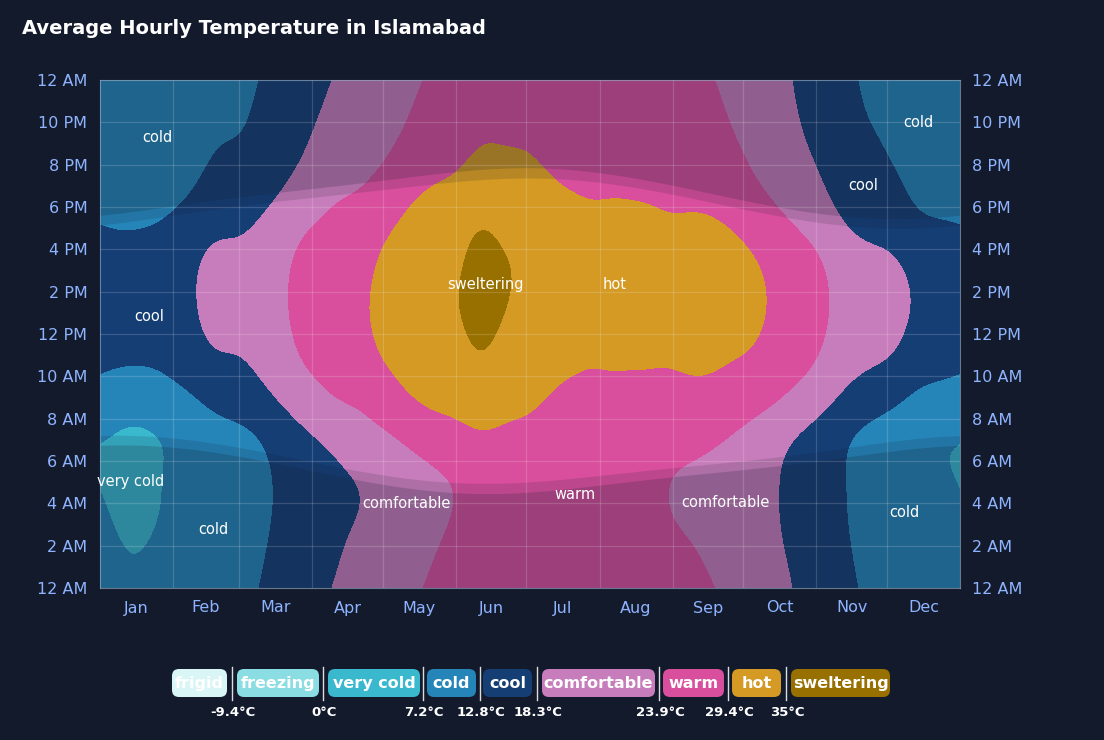

In [5]:
# Fetch data and generate the figure first
df = fetch_hourly()
fig = make_figure(df)

# Save the figure as an image
fig.savefig('islamabad_hourly_temperature.png', dpi=100, facecolor=fig.get_facecolor(), edgecolor='none')

# Save the hourly data to an Excel file
df.to_excel('islamabad_hourly_data.xlsx', index=False)

# Trigger downloads in Google Colab
from google.colab import files
files.download('islamabad_hourly_temperature.png')
files.download('islamabad_hourly_data.xlsx')